# Fase D — Visualizaciones

Ocho visualizaciones construidas a partir de las consultas de la Fase C (`fase_c_sql.ipynb`) ejecutadas contra la bodega en PostgreSQL.

| # | Visualización | Tipo exigido | Consulta base |
|---|---|---|---|
| V1 | Homicidios por año | **Serie de tiempo** | C1 |
| V2 | Top 10 departamentos | **Comparación categórica** | C2 |
| V3 | Quinquenio 2015–19 vs 2020–24 por departamento | **Relación bivariada** | C2 |
| V4 | Concentración en el municipio líder | Comparación categórica | C3 |
| V5 | Mapa de calor día × franja horaria | Bivariada (categórica) | C4 |
| V6 | Mecanismo causal según sexo | Comparación categórica | C5 |
| V7 | Distribución de la edad de las víctimas | **Distribución univariada** | C5 |
| V8 | Escenario del hecho según sexo | Comparación categórica | C6 |

Las figuras también se guardan en `entrega/figuras/` para el informe.

In [1]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.exc import OperationalError, ArgumentError, ProgrammingError

RAIZ = Path.cwd().parent if Path.cwd().name == "entrega" else Path.cwd()
load_dotenv(RAIZ / ".env")
DATABASE_URL = os.getenv("DATABASE_URL")
if not DATABASE_URL:
    raise RuntimeError("No se encontró DATABASE_URL. Copie .env.example a .env y ajústelo.")

try:
    engine = create_engine(DATABASE_URL, pool_pre_ping=True)
    with engine.connect() as conn:
        n = conn.execute(text("SELECT COUNT(*) FROM fact_homicidios")).scalar()
except (ArgumentError, OperationalError) as e:
    raise RuntimeError(f"No fue posible conectar a PostgreSQL con DATABASE_URL: {e}") from None
except ProgrammingError:
    raise RuntimeError("La bodega está vacía: ejecute primero entrega/fase_b_etl.ipynb") from None
print(f"Conectado ✔  fact_homicidios tiene {n:,} filas")


def consultar(sql: str) -> pd.DataFrame:
    return pd.read_sql(text(sql), engine)

Conectado ✔  fact_homicidios tiene 125,284 filas


In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

AZUL, NARANJA, GRIS, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#b8b7b0", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
miles = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", facecolor="white")
    plt.show()

In [3]:
# Consultas de la Fase C (mismo SQL)
C1 = '''
SELECT t.anio,
       SUM(f.cantidad_homicidios)                                   AS homicidios,
       LAG(SUM(f.cantidad_homicidios)) OVER (ORDER BY t.anio)       AS homicidios_anio_anterior,
       ROUND(100.0 * (SUM(f.cantidad_homicidios)
                      - LAG(SUM(f.cantidad_homicidios)) OVER (ORDER BY t.anio))
             / LAG(SUM(f.cantidad_homicidios)) OVER (ORDER BY t.anio), 1) AS variacion_pct
FROM fact_homicidios f
JOIN dim_tiempo t ON f.sk_fecha = t.sk_fecha
GROUP BY t.anio
ORDER BY t.anio;
'''
C2 = '''
SELECT g.departamento,
       SUM(f.cantidad_homicidios) AS total,
       ROUND(100.0 * SUM(f.cantidad_homicidios)
             / SUM(SUM(f.cantidad_homicidios)) OVER (), 1)                    AS participacion_pct,
       SUM(f.cantidad_homicidios) FILTER (WHERE t.anio BETWEEN 2015 AND 2019) AS periodo_2015_2019,
       SUM(f.cantidad_homicidios) FILTER (WHERE t.anio BETWEEN 2020 AND 2024) AS periodo_2020_2024,
       ROUND(100.0 * (SUM(f.cantidad_homicidios) FILTER (WHERE t.anio BETWEEN 2020 AND 2024)
                    - SUM(f.cantidad_homicidios) FILTER (WHERE t.anio BETWEEN 2015 AND 2019))
             / NULLIF(SUM(f.cantidad_homicidios) FILTER (WHERE t.anio BETWEEN 2015 AND 2019), 0), 1)
                                                                              AS cambio_pct
FROM fact_homicidios f
JOIN dim_geografia g ON f.sk_geografia = g.sk_geografia
JOIN dim_tiempo    t ON f.sk_fecha     = t.sk_fecha
WHERE g.departamento <> 'Sin información'
GROUP BY g.departamento
ORDER BY total DESC;
'''
C3 = '''
WITH por_municipio AS (
    SELECT g.departamento, g.municipio, SUM(f.cantidad_homicidios) AS homicidios
    FROM fact_homicidios f
    JOIN dim_geografia g ON f.sk_geografia = g.sk_geografia
    WHERE g.departamento NOT IN ('Sin información', 'Bogotá, D.C.')   -- Bogotá es un único municipio
    GROUP BY g.departamento, g.municipio
),
ranking AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY departamento ORDER BY homicidios DESC) AS puesto,
           SUM(homicidios) OVER (PARTITION BY departamento)                      AS total_departamento
    FROM por_municipio
)
SELECT departamento, municipio AS municipio_lider, homicidios, total_departamento,
       ROUND(100.0 * homicidios / total_departamento, 1) AS concentracion_pct
FROM ranking
WHERE puesto = 1
ORDER BY total_departamento DESC;
'''
C4 = '''
SELECT t.dia_num, t.dia_semana, t.hora_orden, t.rango_hora_3h,
       SUM(f.cantidad_homicidios) AS homicidios,
       ROUND(100.0 * SUM(f.cantidad_homicidios) / SUM(SUM(f.cantidad_homicidios)) OVER (), 2) AS pct
FROM fact_homicidios f
JOIN dim_tiempo t ON f.sk_fecha = t.sk_fecha
WHERE t.dia_num > 0 AND t.hora_orden > 0
GROUP BY t.dia_num, t.dia_semana, t.hora_orden, t.rango_hora_3h
ORDER BY homicidios DESC;
'''
C5 = '''
SELECT v.sexo,
       v.grupo_edad_quinquenal,
       g.zona_hecho,
       m.mecanismo_causal,
       SUM(f.cantidad_homicidios) AS homicidios
FROM fact_homicidios f
JOIN dim_victima   v ON f.sk_victima   = v.sk_victima
JOIN dim_geografia g ON f.sk_geografia = g.sk_geografia
JOIN dim_modalidad m ON f.sk_modalidad = m.sk_modalidad
GROUP BY v.sexo, v.grupo_edad_quinquenal, g.zona_hecho, m.mecanismo_causal
ORDER BY homicidios DESC;
'''
C6 = '''
WITH escenarios AS (
    SELECT v.sexo,
           m.escenario_hecho,
           SUM(f.cantidad_homicidios) AS homicidios,
           ROUND(100.0 * SUM(f.cantidad_homicidios)
                 / SUM(SUM(f.cantidad_homicidios)) OVER (PARTITION BY v.sexo), 1) AS pct_del_sexo,
           RANK() OVER (PARTITION BY v.sexo ORDER BY SUM(f.cantidad_homicidios) DESC) AS puesto
    FROM fact_homicidios f
    JOIN dim_victima   v ON f.sk_victima   = v.sk_victima
    JOIN dim_modalidad m ON f.sk_modalidad = m.sk_modalidad
    WHERE v.sexo IN ('Hombre', 'Mujer')
      AND m.escenario_hecho NOT IN ('Sin Información', 'Otros')
    GROUP BY v.sexo, m.escenario_hecho
)
SELECT sexo, puesto, escenario_hecho, homicidios, pct_del_sexo
FROM escenarios
WHERE puesto <= 5
ORDER BY sexo, puesto;
'''
c1, c2, c3, c4, c5, c6 = (consultar(q) for q in (C1, C2, C3, C4, C5, C6))
print("Consultas ejecutadas ✔")

Consultas ejecutadas ✔


## V1. Serie de tiempo — homicidios por año (C1)

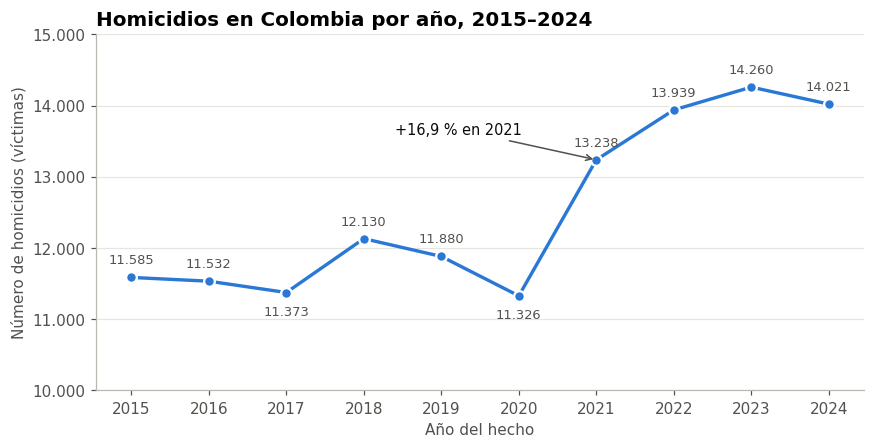

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(c1.anio, c1.homicidios, color=AZUL, lw=2.2, marker="o", ms=7, mec="white", mew=1.5)
for _, r in c1.iterrows():
    abajo = r.anio in (2017, 2020)
    ax.annotate(f"{r.homicidios:,.0f}".replace(",", "."), (r.anio, r.homicidios),
                textcoords="offset points", xytext=(0, -15 if abajo else 9), ha="center", fontsize=8.5, color=TINTA2)
r21 = c1[c1.anio == 2021].iloc[0]
ax.annotate("+16,9 % en 2021", (2021, r21.homicidios), xytext=(2018.4, 13600), color=TINTA,
            arrowprops=dict(arrowstyle="->", color=TINTA2), fontsize=9.5)
ax.set(title="Homicidios en Colombia por año, 2015–2024",
       xlabel="Año del hecho", ylabel="Número de homicidios (víctimas)", ylim=(10000, 15000))
ax.set_xticks(c1.anio); ax.yaxis.set_major_formatter(miles); ax.grid(axis="x", visible=False)
guardar(fig, "v1_serie_anual")

**Insight:** el número anual de homicidios fue estable entre 2015 y 2020 (≈11.300–12.100) y dio un salto de 16,9 % en 2021, tras el mínimo de la pandemia. Desde entonces se sostiene en un nivel más alto (≈14.000 al año); 2024 muestra la primera leve baja, pero sigue 21 % por encima de 2015.

## V2. Comparación categórica — 10 departamentos con más homicidios (C2)

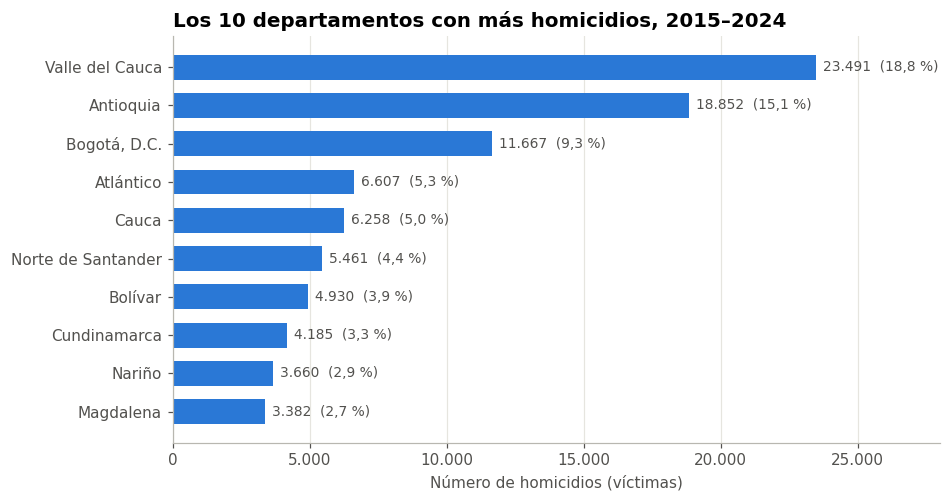

In [5]:
top10 = c2.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top10.departamento, top10.total, color=AZUL, height=0.65)
for y, (v, p) in enumerate(zip(top10.total, top10.participacion_pct)):
    ax.text(v + 250, y, f"{v:,.0f}".replace(",", ".") + f"  ({p:.1f} %)".replace(".", ","),
            va="center", fontsize=9, color=TINTA2)
ax.set(title="Los 10 departamentos con más homicidios, 2015–2024",
       xlabel="Número de homicidios (víctimas)", xlim=(0, 28000))
ax.xaxis.set_major_formatter(miles); ax.grid(axis="y", visible=False)
guardar(fig, "v2_top_departamentos")

**Insight:** Valle del Cauca, Antioquia y Bogotá concentran el 43 % de los homicidios del país y los 10 primeros departamentos el 71 %. Valle del Cauca por sí solo supera a Bogotá y a Atlántico juntos, lo que lo convierte en la prioridad territorial número uno.

## V3. Relación bivariada — homicidios 2015–2019 vs. 2020–2024 por departamento (C2)

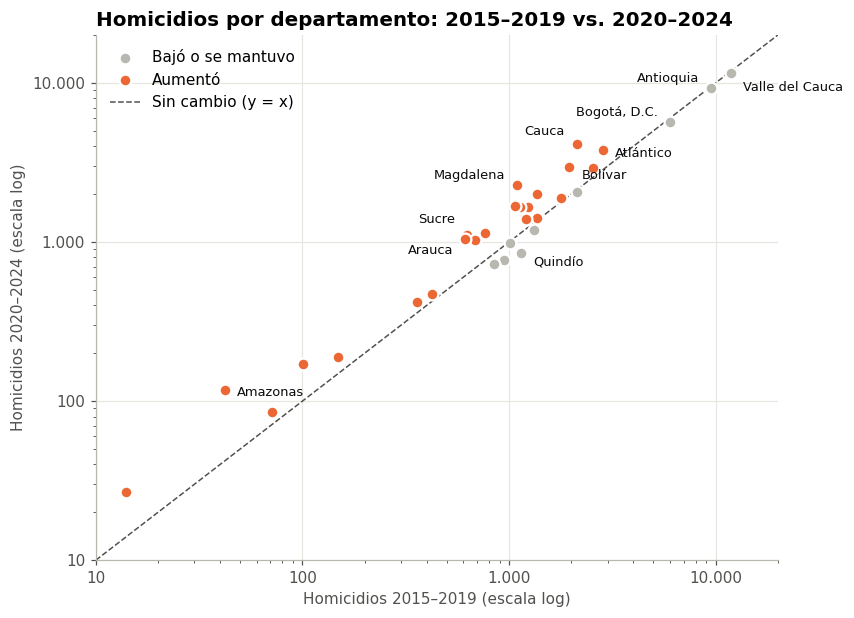

Departamentos que aumentaron: 24 de 33


In [6]:
d = c2.copy()
d["crecio"] = d.periodo_2020_2024 > d.periodo_2015_2019
fig, ax = plt.subplots(figsize=(8, 6.2))
for crecio, color, etiqueta in [(False, GRIS, "Bajó o se mantuvo"), (True, NARANJA, "Aumentó")]:
    s = d[d.crecio == crecio]
    ax.scatter(s.periodo_2015_2019, s.periodo_2020_2024, s=60, color=color, edgecolor="white",
               lw=1.5, label=etiqueta, zorder=3)
lim = [10, 20000]
ax.plot(lim, lim, ls="--", color=TINTA2, lw=1, label="Sin cambio (y = x)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(miles); ax.yaxis.set_major_formatter(miles)
POS = {"Valle del Cauca": (8, -12, "left"), "Antioquia": (-8, 4, "right"), "Bogotá, D.C.": (-8, 4, "right"),
       "Cauca": (-8, 6, "right"), "Atlántico": (8, -4, "left"), "Magdalena": (-8, 4, "right"),
       "Bolívar": (8, -8, "left"), "Sucre": (-8, 8, "right"), "Arauca": (-8, -10, "right"),
       "Quindío": (8, -8, "left"), "Amazonas": (8, -4, "left")}
for dep, (dx, dy, ha) in POS.items():
    r = d[d.departamento == dep].iloc[0]
    ax.annotate(dep, (r.periodo_2015_2019, r.periodo_2020_2024), xytext=(dx, dy),
                textcoords="offset points", ha=ha, fontsize=8.5, color=TINTA)
ax.set(title="Homicidios por departamento: 2015–2019 vs. 2020–2024",
       xlabel="Homicidios 2015–2019 (escala log)", ylabel="Homicidios 2020–2024 (escala log)")
ax.legend(frameon=False, loc="upper left")
guardar(fig, "v3_quinquenios_departamentos")
print(f"Departamentos que aumentaron: {d.crecio.sum()} de {len(d)}")

**Insight:** los dos periodos están muy correlacionados (los departamentos violentos siguen siéndolo), pero la mayoría de los puntos queda sobre la diagonal: aumentaron sus homicidios. Los que más se alejan hacia arriba son Magdalena (+109 %), Cauca (+95 %), Sucre, Arauca y Bolívar, mientras que los grandes centros (Valle, Antioquia, Bogotá) quedan justo debajo de la línea: el crecimiento está en la periferia.

## V4. Comparación categórica — peso del municipio líder en su departamento (C3)

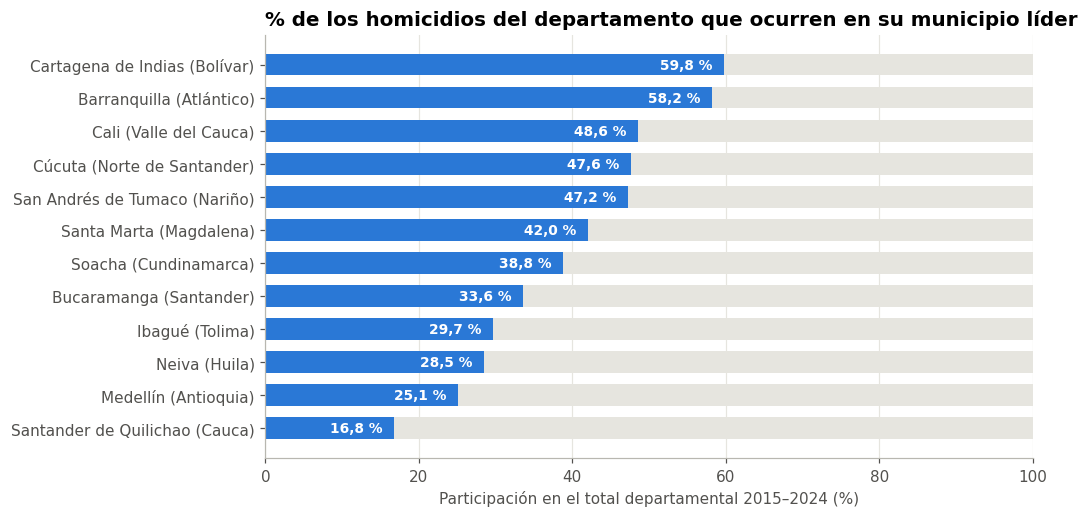

In [7]:
d4 = c3.head(12).sort_values("concentracion_pct")
etq = d4.municipio_lider + " (" + d4.departamento + ")"
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etq, d4.concentracion_pct, color=AZUL, height=0.65)
ax.barh(etq, 100 - d4.concentracion_pct, left=d4.concentracion_pct, color="#e6e5df", height=0.65)
for y, v in enumerate(d4.concentracion_pct):
    ax.text(v - 1.5, y, f"{v:.1f} %".replace(".", ","), va="center", ha="right", color="white",
            fontsize=9, fontweight="bold")
ax.set(title="% de los homicidios del departamento que ocurren en su municipio líder",
       xlabel="Participación en el total departamental 2015–2024 (%)", xlim=(0, 100))
ax.grid(axis="y", visible=False)
guardar(fig, "v4_concentracion_municipal")

**Insight:** en Bolívar, Atlántico, Valle, Norte de Santander y Nariño un solo municipio concentra casi la mitad o más de los homicidios, así que intervenir Cartagena, Barranquilla, Cali, Cúcuta o Tumaco impacta a todo el departamento. Cauca es el caso opuesto: su municipio líder apenas llega al 16,8 %, señal de una violencia dispersa y rural.

## V5. Mapa de calor — día de la semana × franja horaria (C4)

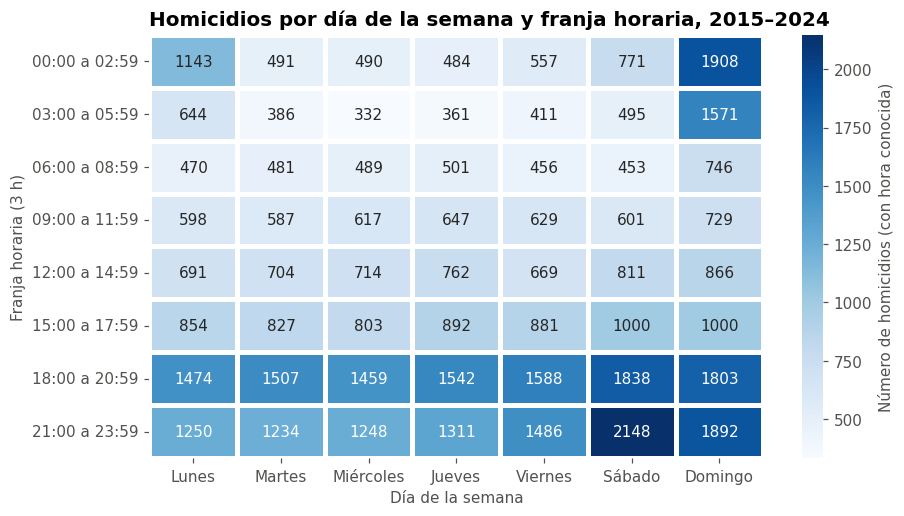

In [8]:
calor = (c4.pivot_table(index=["hora_orden", "rango_hora_3h"], columns=["dia_num", "dia_semana"],
                        values="homicidios").droplevel(0).droplevel(0, axis=1))
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(calor, cmap="Blues", annot=True, fmt=".0f", linewidths=2, linecolor="white",
            cbar_kws={"label": "Número de homicidios (con hora conocida)"}, ax=ax)
ax.set(title="Homicidios por día de la semana y franja horaria, 2015–2024",
       xlabel="Día de la semana", ylabel="Franja horaria (3 h)")
ax.tick_params(axis="y", rotation=0)
guardar(fig, "v5_calor_dia_hora")

**Insight:** el riesgo se dispara entre las 18:00 y las 03:00, y sobre todo en la noche del sábado al domingo (sábado 21–24 h: 2.148 casos; domingo 00–03 h: 1.908). La madrugada del lunes también sobresale por los puentes festivos. *Nota:* solo el 41 % de los registros tiene la hora informada.

## V6. Comparación categórica — mecanismo causal según sexo de la víctima (C5)

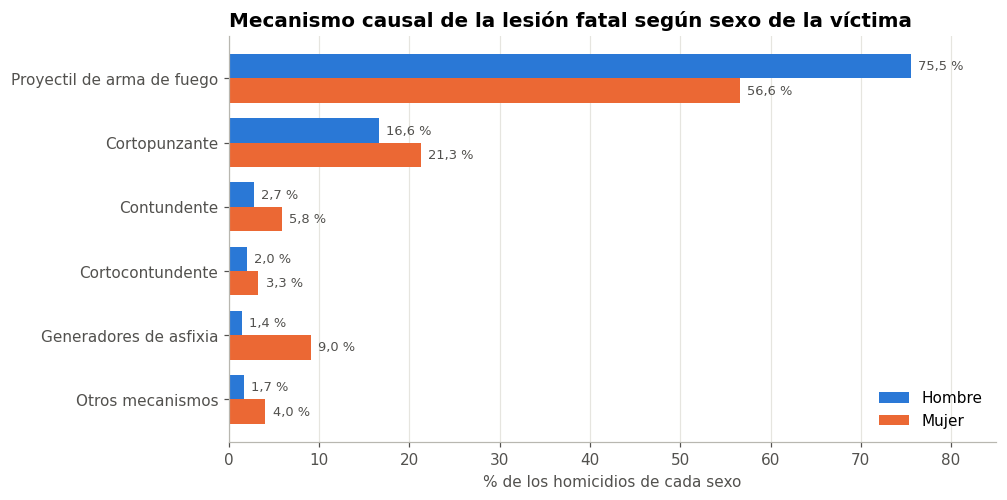

In [9]:
mec = (c5[c5.sexo.isin(["Hombre", "Mujer"])]
       .pivot_table(index="mecanismo_causal", columns="sexo", values="homicidios", aggfunc="sum").fillna(0))
mec = 100 * mec / mec.sum()
principales = mec.sort_values("Hombre", ascending=False).head(5).index
mec = pd.concat([mec.loc[principales], mec.drop(principales).sum().to_frame("Otros mecanismos").T]).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 4.8))
y = range(len(mec)); h = 0.38
ax.barh([i + h/2 for i in y], mec.Hombre, height=h, color=AZUL, label="Hombre")
ax.barh([i - h/2 for i in y], mec.Mujer, height=h, color=NARANJA, label="Mujer")
for i, (a, b) in enumerate(zip(mec.Hombre, mec.Mujer)):
    ax.text(a + 0.8, i + h/2, f"{a:.1f} %".replace(".", ","), va="center", fontsize=8.5, color=TINTA2)
    ax.text(b + 0.8, i - h/2, f"{b:.1f} %".replace(".", ","), va="center", fontsize=8.5, color=TINTA2)
ax.set_yticks(list(y)); ax.set_yticklabels(mec.index)
ax.set(title="Mecanismo causal de la lesión fatal según sexo de la víctima",
       xlabel="% de los homicidios de cada sexo", xlim=(0, 85))
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
guardar(fig, "v6_mecanismo_sexo")

**Insight:** el arma de fuego domina en ambos sexos, pero su peso cae de 75,5 % en hombres a 56,6 % en mujeres. En ellas la asfixia es seis veces más frecuente (9,0 % vs. 1,4 %) y también pesan más el arma cortopunzante y el objeto contundente: mecanismos de contacto cercano, asociados a agresores conocidos.

## V7. Distribución univariada — edad de las víctimas (C5)

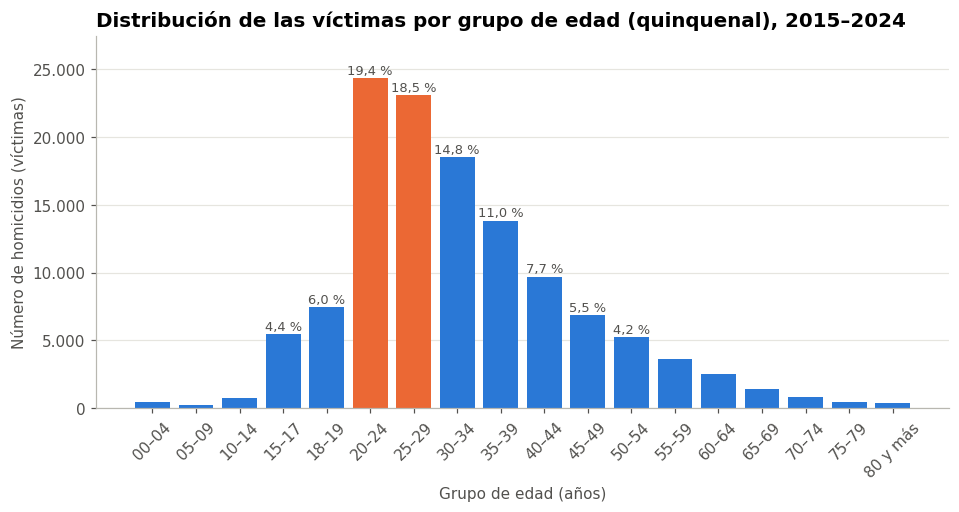

Víctimas de 18 a 34 años: 58.6 %


In [10]:
edad = (c5[c5.grupo_edad_quinquenal.str.startswith("(")]
        .groupby("grupo_edad_quinquenal")["homicidios"].sum().sort_index())
edad.index = edad.index.str.strip("()").str.replace(" a ", "–")
pct = 100 * edad / edad.sum()
colores = [NARANJA if g in ("20–24", "25–29") else AZUL for g in edad.index]

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(edad.index, edad.values, color=colores, width=0.8)
for x, (v, p) in enumerate(zip(edad.values, pct.values)):
    if p >= 4:
        ax.text(x, v + 300, f"{p:.1f} %".replace(".", ","), ha="center", fontsize=8.5, color=TINTA2)
ax.set(title="Distribución de las víctimas por grupo de edad (quinquenal), 2015–2024",
       xlabel="Grupo de edad (años)", ylabel="Número de homicidios (víctimas)", ylim=(0, 27500))
ax.yaxis.set_major_formatter(miles); ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=45)
guardar(fig, "v7_distribucion_edad")
print(f"Víctimas de 18 a 34 años: {pct[['18–19','20–24','25–29','30–34']].sum():.1f} %")

**Insight:** la distribución es asimétrica a la derecha con moda en 20–24 años: los grupos 20–24 y 25–29 (en naranja) suman casi 38 % de las víctimas, y entre los 18 y 34 años se concentra el 58,6 %. Después de los 35 la frecuencia cae de forma sostenida; la prevención debe enfocarse en jóvenes adultos.

## V8. Comparación categórica — escenario del hecho según sexo (C6)

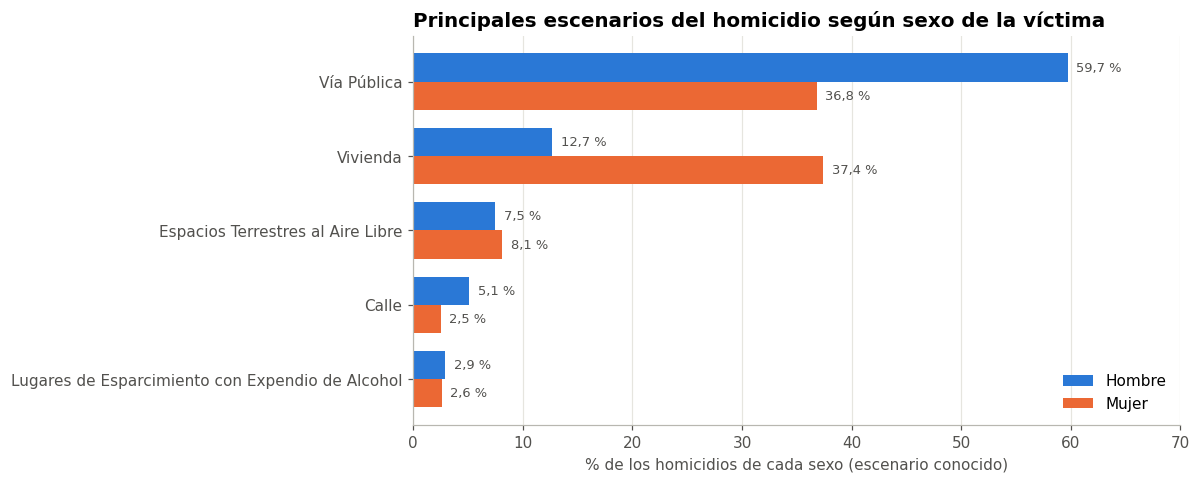

In [11]:
esc = c6.copy()
esc["escenario"] = esc.escenario_hecho.str.replace(r"\s*\(.*\)", "", regex=True)
tabla = esc.pivot_table(index="escenario", columns="sexo", values="pct_del_sexo").fillna(0)
tabla = tabla.loc[tabla.max(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 4.6))
y = range(len(tabla)); h = 0.38
ax.barh([i + h/2 for i in y], tabla.Hombre, height=h, color=AZUL, label="Hombre")
ax.barh([i - h/2 for i in y], tabla.Mujer, height=h, color=NARANJA, label="Mujer")
for i, (a, b) in enumerate(zip(tabla.Hombre, tabla.Mujer)):
    ax.text(a + 0.8, i + h/2, f"{a:.1f} %".replace(".", ","), va="center", fontsize=8.5, color=TINTA2)
    ax.text(b + 0.8, i - h/2, f"{b:.1f} %".replace(".", ","), va="center", fontsize=8.5, color=TINTA2)
ax.set_yticks(list(y)); ax.set_yticklabels(tabla.index)
ax.set(title="Principales escenarios del homicidio según sexo de la víctima",
       xlabel="% de los homicidios de cada sexo (escenario conocido)", xlim=(0, 70))
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
guardar(fig, "v8_escenario_sexo")

**Insight:** el 59,7 % de los hombres muere en la vía pública, mientras que para las mujeres la vivienda es el primer escenario (37,4 %), casi el triple que en hombres (12,7 %). Esto confirma que el homicidio de mujeres está ligado al ámbito doméstico y requiere prevención de violencia intrafamiliar y de pareja.